<a href="https://colab.research.google.com/github/lianamadoyan/coursework_graphs/blob/main/airline_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!wget -q https://raw.githubusercontent.com/jpatokal/openflights/master/data/routes.dat
!ls

routes.dat  routes.dat.1  sample_data


In [11]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

cols = ["airline", "airline_id", "src", "src_id", "dst", "dst_id", "codeshare", "stops", "equipment"]
routes = pd.read_csv("routes.dat", header=None, names=cols, na_values=["\\N"])
print(routes.shape)
print(routes[["src", "dst"]].head())

(67663, 9)
   src  dst
0  AER  KZN
1  ASF  KZN
2  ASF  MRV
3  CEK  KZN
4  CEK  OVB


In [12]:
G = nx.from_pandas_edgelist(routes, "src", "dst")
G.remove_edges_from(nx.selfloop_edges(G))
print(G.number_of_nodes(), G.number_of_edges())

3425 19256


In [13]:
giant_nodes = max(nx.connected_components(G), key=len)
H = G.subgraph(giant_nodes).copy()
print(H.number_of_nodes(), H.number_of_edges())

3397 19230


In [14]:
degrees = [k for _, k in H.degree()]

print("Density:", nx.density(H))
print("Average degree:", np.mean(degrees))
print("Max degree:", max(degrees))
print("Median degree:", np.median(degrees))
print("Average clustering:", nx.average_clustering(H))

Density: 0.003333849967389642
Average degree: 11.321754489255225
Max degree: 248
Median degree: 3.0
Average clustering: 0.48833620245296055


In [15]:
print("Avg shortest path:", nx.average_shortest_path_length(H))
print("Diameter:", nx.diameter(H))

Avg shortest path: 4.103241167898093
Diameter: 13


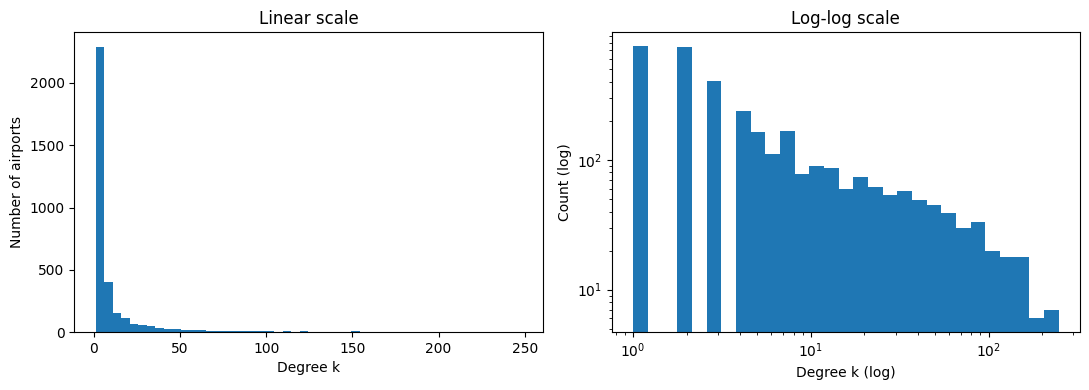

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Left: linear scale, most airports are piled up near zero
ax[0].hist(degrees, bins=50)
ax[0].set_xlabel("Degree k")
ax[0].set_ylabel("Number of airports")
ax[0].set_title("Linear scale")

# Right: log-log scale with logarithmic bins, a heavy tail shows up as a roughly straight line
ax[1].hist(degrees, bins=np.logspace(0, np.log10(max(degrees)), 30))
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("Degree k (log)")
ax[1].set_ylabel("Count (log)")
ax[1].set_title("Log-log scale")

plt.tight_layout()
plt.show()

In [17]:
deg = nx.degree_centrality(H)        # who has the most direct connections
clo = nx.closeness_centrality(H)     # who is closest to everyone else
btw = nx.betweenness_centrality(H)   # who lies on the most shortest paths (bridges)

def top_nodes(c, k=5):
    # Sort (node, value) pairs by value, largest first, and keep the first k
    return sorted(c.items(), key=lambda x: x[1], reverse=True)[:k]

for name, c in [("Degree", deg), ("Betweenness", btw), ("Closeness", clo)]:
    print(name, [(a, round(v, 3)) for a, v in top_nodes(c)])

Degree [('AMS', 0.073), ('FRA', 0.072), ('CDG', 0.071), ('IST', 0.069), ('ATL', 0.064)]
Betweenness [('ANC', 0.074), ('LAX', 0.066), ('CDG', 0.063), ('DXB', 0.057), ('FRA', 0.052)]
Closeness [('FRA', 0.402), ('CDG', 0.399), ('LHR', 0.397), ('AMS', 0.393), ('DXB', 0.393)]


In [ ]:
def giant(G):
    # Largest connected component of any graph
    return G.subgraph(max(nx.connected_components(G), key=len))

n, m = H.number_of_nodes(), H.number_of_edges()
Cs, Ls = [], []

# Random graphs with the same number of nodes and edges as the real network.
# 10 samples are enough here: each one takes ~30 s and they are very similar to each other
for i in range(10):
    R = giant(nx.gnm_random_graph(n, m, seed=i))
    Cs.append(nx.average_clustering(R))
    Ls.append(nx.average_shortest_path_length(R))

print("C real:", nx.average_clustering(H), " C ER:", np.mean(Cs))
print("L real:", nx.average_shortest_path_length(H), " L ER:", np.mean(Ls))